<a href="https://colab.research.google.com/github/Joanie-lab/breast-cancer-diagnostic-analysis/blob/main/Project_Breast_Cancer_Diagnostic_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Breast Cancer Diagnostic Data Analysis

## Introduction

Objective: This project explores how cell measurements differ between benign and malignant breast tissue samples, and tests whether a simple model can tell them apart.

Data: I used the Wisconsin Breast Cancer Diagnostic dataset from the UCI Machine Learning Repository. It contains 569 samples, each described by 30 measurements, which come from 10 characteristics of the cell nuclei (such as radius, texture and area), each recorded as a mean, a standard error and a worst value. Each sample is labelled as either malignant or benign.

Approach: I cleaned and explored the data, visualised selected measurements (such as radius, texture and concavity) to compare benign and malignant samples. I split the data into training and test sets, scaled the features and trained a logistic regression model. I evaluated it using a confusion matrix, sensitivity (recall) and specificity.

Result: The model achieved 98.25% accuracy, with a sensitivity of 97.6% and a specificity of 98.6% on the test set.

Note: This is a learning project and not a clinical diagnostic tool.



## Loading and inspecting the data

In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

I loaded the dataset using scikit-learn, which contains the Wisconsin Breast Cancer Diagnostic dataset from the UCI repository.

In [2]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape

(569, 31)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [6]:
df['target'].unique()

array([0, 1])

The number of rows in the dataset is 569 with 31 columns, of which 30 are measurements of cell nuclei and 1 represents the target column. The data consists of numerical values only. Every row represents one tissue sample. The measurements are of greatly varying scales (mean area measurement is in the hundreds and mean smoothness is around 0.1).

In [7]:
df.columns.tolist()

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension',
 'target']

In [8]:
data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [9]:
[col for col in df.columns if 'mean' in col]

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension']

In [10]:
[col for col in df.columns if 'error' in col]

['radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error']

In [11]:
[col for col in df.columns if 'worst' in col]

['worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension']

The 30 measurements are based on 10 characteristics of the nuclei in the cell (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension). All of them are measured in three ways – mean, standard error, and worst. Worst is the average of the three largest values in the sample. The target column contains the result: 0 = malignant, 1 = benign.

In [12]:
df.isnull().sum().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

## Data cleaning

There were no missing values and no duplicates identified in the dataset. No cleaning was necessary prior to analysis.

## Exploring the data

In total, there are 357 benign instances (62.7%) and 212 malignant instances (37.3%) within the data set. There is a slight imbalance between the two classes, which means that accuracy alone will not be an adequate way of evaluating the model.

In [14]:
df['target'].value_counts()

,count
target,
1,357
0,212


In [15]:
df['target'].value_counts(normalize=True) * 100

,proportion
target,
1,62.741652
0,37.258348


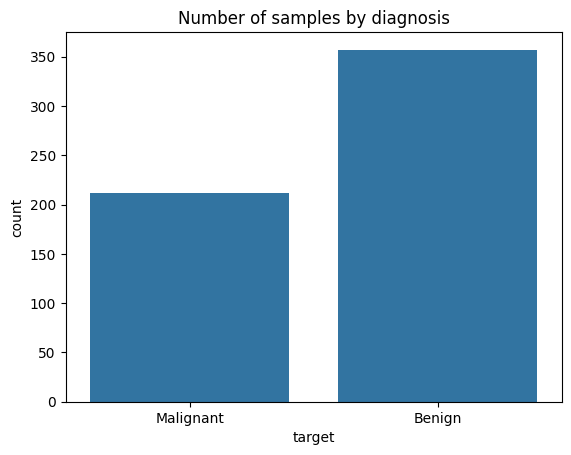

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='target', data=df)
plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.title('Number of samples by diagnosis')
plt.show()

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

df['diagnosis'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

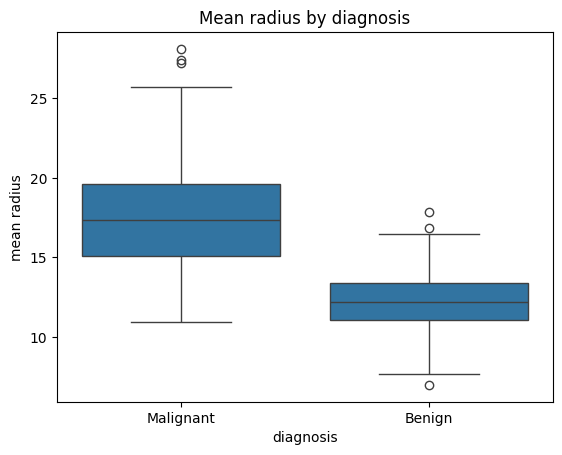

In [18]:
sns.boxplot(x='diagnosis', y='mean radius', data=df)
plt.title('Mean radius by diagnosis')
plt.show()

It is clearly observed that the malignant tumors have a greater mean radius compared to the benign ones. In case of the malignant tumors, the median is 17 whereas in case of the benign tumors, the median is 12. The two boxes overlap very little.

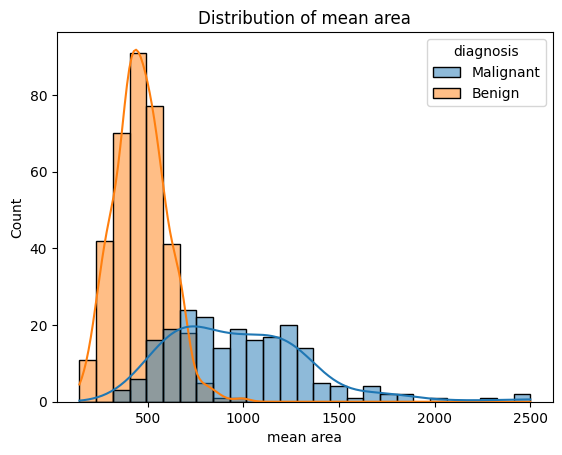

In [19]:
sns.histplot(data=df, x='mean area', hue='diagnosis', kde=True)
plt.title('Distribution of mean area')
plt.show()

Benign samples are concentrated at smaller areas, around the 700 mark or lower, whereas malignant samples are scattered across larger values that go beyond 1,000. There is not much overlapping between the two, making mean area a good criterion to separate the two. Additionally, the malignant samples are more dispersed.

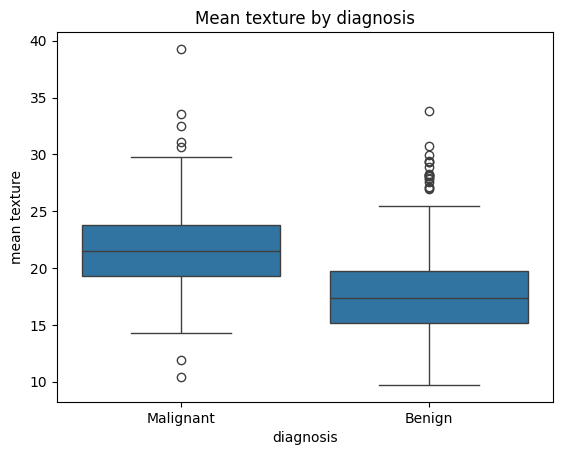

In [20]:
sns.boxplot(x='diagnosis', y='mean texture', data=df)
plt.title('Mean texture by diagnosis')
plt.show()

The malignant tumors have a mean texture which is slightly higher with a median value of about 21.5 compared to 17.4 for benign tumors. Nevertheless, there is an overlapping of the two boxes, and hence the texture alone cannot be used to differentiate between the two.

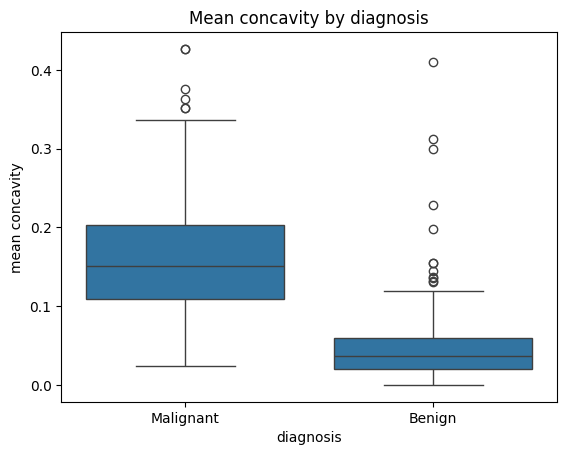

In [21]:
sns.boxplot(x='diagnosis', y='mean concavity', data=df)
plt.title('Mean concavity by diagnosis')
plt.show()

Malignant samples show significantly larger mean concavity (with a median value of about 0.15) than benign samples (whose median is around 0.04). It means that malignant cells feature deeper concavities in the perimeters of the cell outline. There is very little overlapping of distributions, which makes concavity a strong measurement.

##Summary of exploration:
Malignant samples tend to possess larger and more irregular cell nuclei compared to their benign counterparts. Radius, area, and concavity appeared to differentiate the groups significantly, but texture possessed considerable overlap between the classes. Radius, perimeter, and area all deal with size, hence tend to move together. From these trends, a model should be able to distinguish the groups reasonably well, but no single measurement is enough on its own.

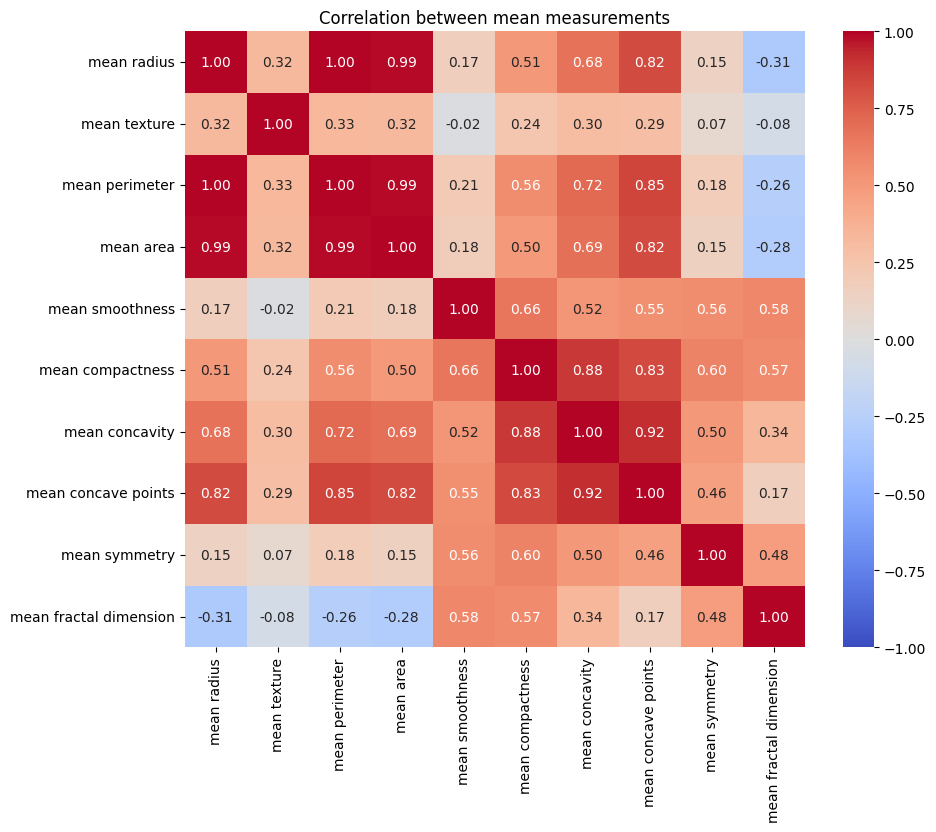

In [22]:
mean_cols = [col for col in df.columns if 'mean' in col]

plt.figure(figsize=(10, 8))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between mean measurements')
plt.show()

As can be seen from the heatmap, radius, perimeter, and area have nearly perfect correlation because they all refer to the size of the nucleus. Likewise, concavity, concave points, and compactness are highly correlated since they all relate to the irregularity of the cell. However, texture is hardly correlated with any other measurement and hence provides unique information. This means that the majority of the measurements overlap in terms of what they measure and therefore it is hard to tell which one is more important than others.

When several measurements carry almost the same information, the model can still predict well, but we can’t reliably tell which one matters most.

## Model building

The 30 measurement features were separated from the diagnosis target and the data set was split into a training set (80%, 455 data) and a test set (20%, 114 data). The stratification technique was implemented in order to preserve the same ratio of benign and malignant cases for both the data set. The test data set was kept aside for the last phase.

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(['target', 'diagnosis'], axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [24]:
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [25]:
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

target
1    62.637363
0    37.362637
Name: proportion, dtype: float64
target
1    63.157895
0    36.842105
Name: proportion, dtype: float64


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

The measurements have values on completely different scales (mean area is in the hundreds, whereas that of smoothness is around 0.1). As such, I standardised the features. Scaling was done on the training set only, after which it was used on the test set. This was to prevent any leakage of information from the test set.

In [27]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [28]:
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

Predicted: [0 1 0 1 0 1 1 0 0 0]
Actual:    [0 1 0 1 0 1 1 0 0 0]


In [29]:
model.predict_proba(X_test_scaled)[:5]

array([[9.99999941e-01, 5.88824186e-08],
       [1.13351672e-05, 9.99988665e-01],
       [9.93589175e-01, 6.41082462e-03],
       [4.66491463e-01, 5.33508537e-01],
       [9.99999999e-01, 6.52500097e-10]])

I trained the logistic regression model using the scaled training data set (455 samples). It understands the relationship between the 30 features and the diagnosis and calculates the probability of being benign for a given sample. I used it to make predictions on the 114 unseen test samples.

In [30]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 98.25%


In [31]:
correct = (y_pred == y_test.values).sum()
total = len(y_test)
print(f"{correct} correct out of {total}")

112 correct out of 114


The model was able to classify 112 out of the 114 testing samples correctly. Its accuracy therefore is 98.25%, which is a lot better than the 63% of accuracy that could have been gotten by always predicting that the sample was benign. But accuracy cannot tell us what mistakes the algorithm is making, so it also needed other tests.

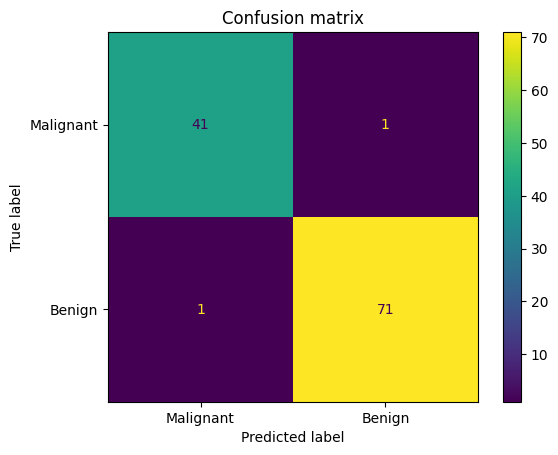

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Malignant', 'Benign']).plot()
plt.title('Confusion matrix')
plt.show()

In [33]:
print(cm)

[[41  1]
 [ 1 71]]


From the confusion matrix, we see that the algorithm classified 41 malignant samples and 71 benign samples correctly. It failed to classify 1 malignant sample, predicting it to be benign, and made one false prediction, predicting a benign sample as malignant. Missing a malignant sample is the critical mistake here.

In [34]:
caught = cm[0, 0]          # malignant correctly identified
missed = cm[0, 1]          # malignant predicted as benign
false_alarms = cm[1, 0]    # benign predicted as malignant
cleared = cm[1, 1]         # benign correctly identified

sensitivity = caught / (caught + missed)
specificity = cleared / (cleared + false_alarms)

print(f"Sensitivity: {sensitivity:.1%}")
print(f"Specificity: {specificity:.1%}")

Sensitivity: 97.6%
Specificity: 98.6%


In [35]:
from sklearn.metrics import recall_score

print("Sensitivity (malignant recall):", round(recall_score(y_test, y_pred, pos_label=0), 3))
print("Specificity (benign recall):", round(recall_score(y_test, y_pred, pos_label=1), 3))

Sensitivity (malignant recall): 0.976
Specificity (benign recall): 0.986


The sensitivity (recall) of the model was 97.6%, where the model detected 41 out of the 42 malignant samples in the test dataset. The specificity of the model was 98.6%, where the model detected 71 out of 72 benign samples. The model failed to detect one malignant sample, which is the more critical error in diagnostics.

## Findings

**What the data showed:** The malignant samples had larger and irregular nuclei compared to benign samples. Radius, area, and concavity were more helpful in distinguishing between the two types of samples, while texture did not provide much information because it overlapped. Radius, perimeter and area all measure the size of the nucleus, so they moved together.

**Model performance:** The logistic regression model classified 112 out of 114 test samples correctly, an accuracy of 98.25%. This is much higher than the 63% that would be achieved by always predicting benign.

**Errors:** The model was able to detect 41 out of 42 cancer cases (with sensitivity 97.6%), while clearing 71 out of 72 benign samples (with specificity 98.6%). The model made one false positive (a false alarm) and one false negative (a missed cancer).

**What it means:** These results indicate that there is sufficient information contained in the simple measurements of cells to distinguish most malignant from benign samples. The error in the one cancer sample missed is, however, the more serious type of error, so improving sensitivity should be the priority in any practical diagnostic use.”



## Limitations

1. Small dataset. There are only 569 samples in the dataset, while the number of instances in the test set is 114. Given that there are only 42 instances of malignant cases in the test set, the error of just one instance can significantly influence the sensitivity.

2. Imbalanced classes. Around 63% are non-cancerous and 37% are cancerous. The skewing is slight, but it shows that accuracy alone could be deceptive, which is why I examined sensitivity and specificity in addition to accuracy.

3. One model and one split. A logistic regression model was built in one go and evaluated against one train-test split. I have not tested this against other models or done cross-validation so can’t comment if the outcome is stable enough to choose a different model instead.

4. Related measurements. Information contained in radius, perimeter, and area is highly correlated. This does not affect prediction much; however, I cannot confidently identify the importance of any one of these measurements individually.

5. Not a clinical tool. This is a learning project. In actual diagnosis, much more than 30 measures will be required, including history, imaging, consultations with specialists, and laboratory tests. The data is also taken from a single source, so the algorithm may not perform equally well on patients from other hospitals.

6. Missed cancers. One of the malignant samples was not picked by the model. This would have been a serious issue in practice, since even one missed cancer case would be a problem, and the model would require much more testing before being used.

In order to improve upon this project, I would apply cross validation to come up with a more reliable estimate, compare logistic regression to other models, and explore methods to increase sensitivity.